# 📊 CodeAlpha Data Science Internship — Task 4: Sales Prediction using Python
---
**Internship Role:** Data Science Intern  
**Domain:** Machine Learning & Predictive Modeling  
**Project:** Sales Prediction based on Advertising Expenditures  

---
### 📌 Problem Overview
In competitive business environments, marketing departments allocate advertising budgets across multiple channels such as **Television (TV)**, **Radio**, and **Newspapers**. A fundamental business challenge is understanding:
1. *How strongly does each advertising channel impact overall product sales?*
2. *Can we accurately forecast future sales based on planned marketing spend?*
3. *How should marketing leaders optimize budget allocation to maximize Return on Investment (ROI)?*

This project demonstrates the full end-to-end Data Science workflow:
- **Data Ingestion & Cleaning**
- **Exploratory Data Analysis (EDA)**
- **Categorical Feature Demonstration**
- **Train-Test Splitting (80/20)**
- **Regression Modeling** (*Multiple Linear Regression* vs. *Random Forest Regressor*)
- **Model Evaluation** (*MAE*, *RMSE*, *R²*)
- **Residual Diagnostics & Visualizations**
- **Actionable Business Strategy & Budget Allocation Insights**


In [1]:
# Import fundamental data manipulation, visualization, and ML libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Configure visualization settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("✅ All required libraries imported successfully!")


✅ All required libraries imported successfully!


## 1. 📂 Data Ingestion & Initial Inspection
We load the real **Advertising** dataset (`Advertising.csv`) and examine its basic structural properties: dimensions, feature data types, and initial records.


In [2]:
# Load the dataset
df = pd.read_csv('Advertising.csv')

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Dataset Info ---")
df.info()


Dataset Shape: 200 rows, 5 columns

--- First 5 Rows ---


,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9



--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


## 2. 🧹 Data Cleaning & Preprocessing
Data cleaning ensures reliable, trustworthy machine learning results:
1. **Drop redundant columns**: The `Unnamed: 0` column is simply an original CSV serial index and carries no predictive value.
2. **Missing value verification**: Verify whether any entries contain `NaN` / null values.
3. **Duplicate row checks**: Ensure every observation is unique.
4. **Summary statistics**: Calculate central tendency (mean, median), dispersion (std), and ranges.


In [3]:
# 1. Drop redundant serial index column if present
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])
    print("Dropped redundant 'Unnamed: 0' column.")

# 2. Check for missing values
missing_vals = df.isnull().sum()
print("\nMissing values per feature:")
print(missing_vals)

# 3. Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"\nDuplicate rows found: {duplicates}")

# 4. Descriptive Statistics
print("\nDescriptive Statistics (Summary Table):")
display(df.describe().round(2))


Dropped redundant 'Unnamed: 0' column.

Missing values per feature:
TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

Duplicate rows found: 0

Descriptive Statistics (Summary Table):


,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


## 3. 🏷️ Categorical Feature Demonstration (Task Requirement #5)
In this canonical Advertising dataset, expenditures across channels are continuous numerical variables (`TV`, `Radio`, `Newspaper` in thousands of dollars).

However, in many real-world enterprise settings, datasets also include categorical attributes such as:
- **`Platform`**: (e.g., *Google Search, YouTube, Instagram, TV*)
- **`Target_Segment`**: (e.g., *Youth, Working Professionals, Seniors*)

To fulfill Task Requirement #5 and demonstrate how categorical attributes are encoded in a scikit-learn workflow, we construct an illustrative categorical attribute `Dominant_Platform` (the channel receiving the highest spend for that observation) and demonstrate **One-Hot Encoding** (`pd.get_dummies`).


In [4]:
# Derive illustrative categorical platform feature
df_demo = df.copy()
channels = ['TV', 'Radio', 'Newspaper']
df_demo['Dominant_Platform'] = df_demo[channels].idxmax(axis=1)

print("Distribution of Derived Categorical Feature ('Dominant_Platform'):")
print(df_demo['Dominant_Platform'].value_counts())

# Perform One-Hot Encoding (converting string categories into binary columns)
encoded_platforms = pd.get_dummies(df_demo['Dominant_Platform'], prefix='Platform', dtype=int)

print("\nSample of One-Hot Encoded Features:")
display(encoded_platforms.head())


Distribution of Derived Categorical Feature ('Dominant_Platform'):
Dominant_Platform
TV           171
Newspaper     19
Radio         10
Name: count, dtype: int64

Sample of One-Hot Encoded Features:


,Platform_Newspaper,Platform_Radio,Platform_TV
0,0,0,1
1,1,0,0
2,1,0,0
3,0,0,1
4,0,0,1


## 4. 📈 Exploratory Data Analysis (EDA)
EDA helps us discover patterns, trends, and correlations between advertising budgets and resulting sales.
We explore:
- Distribution histograms with Kernel Density Estimates (KDE)
- Bivariate scatter plots with fitted regression trendlines
- Correlation heatmap matrix


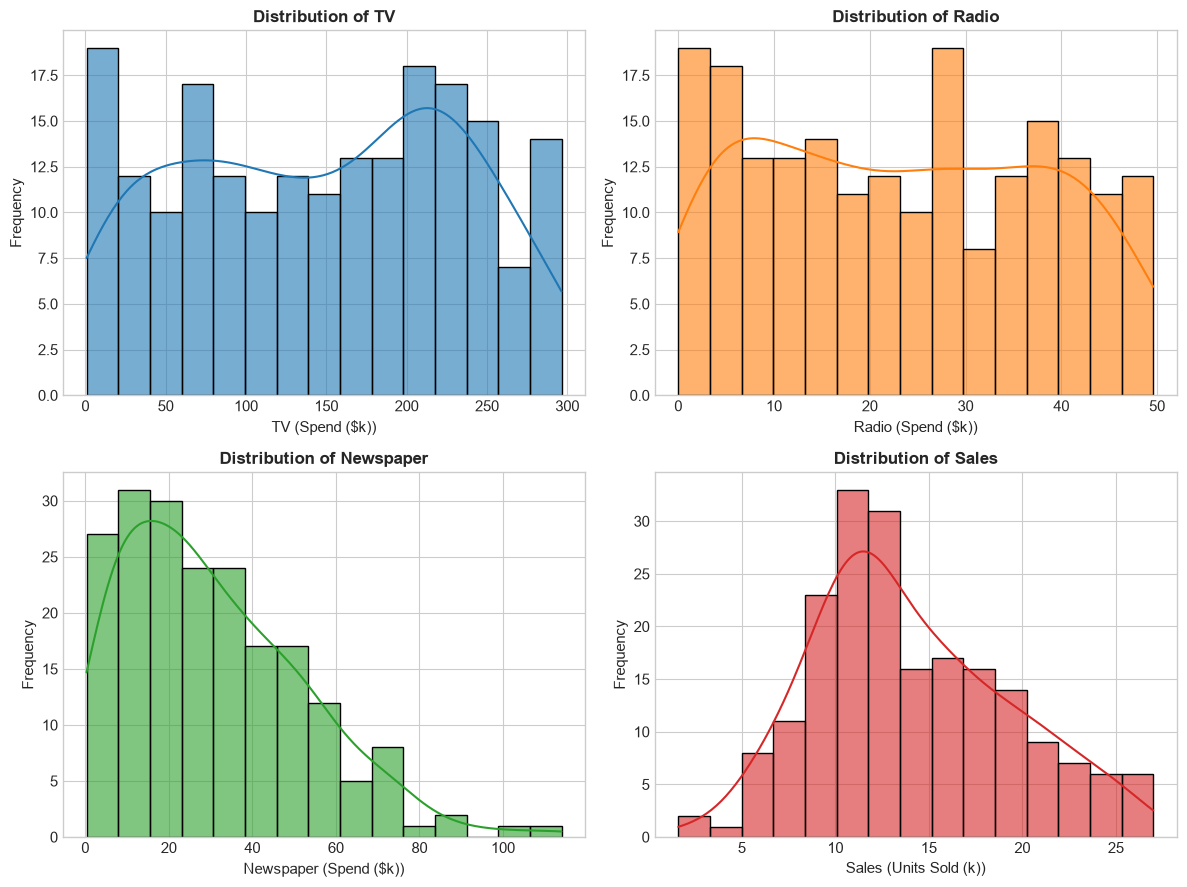

In [5]:
# 1. Feature Distributions
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
palette = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
cols = ['TV', 'Radio', 'Newspaper', 'Sales']
units = ['Spend ($k)', 'Spend ($k)', 'Spend ($k)', 'Units Sold (k)']

for idx, (col, unit, color) in enumerate(zip(cols, units, palette)):
    ax = axes[idx // 2, idx % 2]
    sns.histplot(df[col], kde=True, ax=ax, color=color, bins=15, edgecolor='black', alpha=0.6)
    ax.set_title(f"Distribution of {col}", fontsize=12, fontweight='bold')
    ax.set_xlabel(f"{col} ({unit})")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()


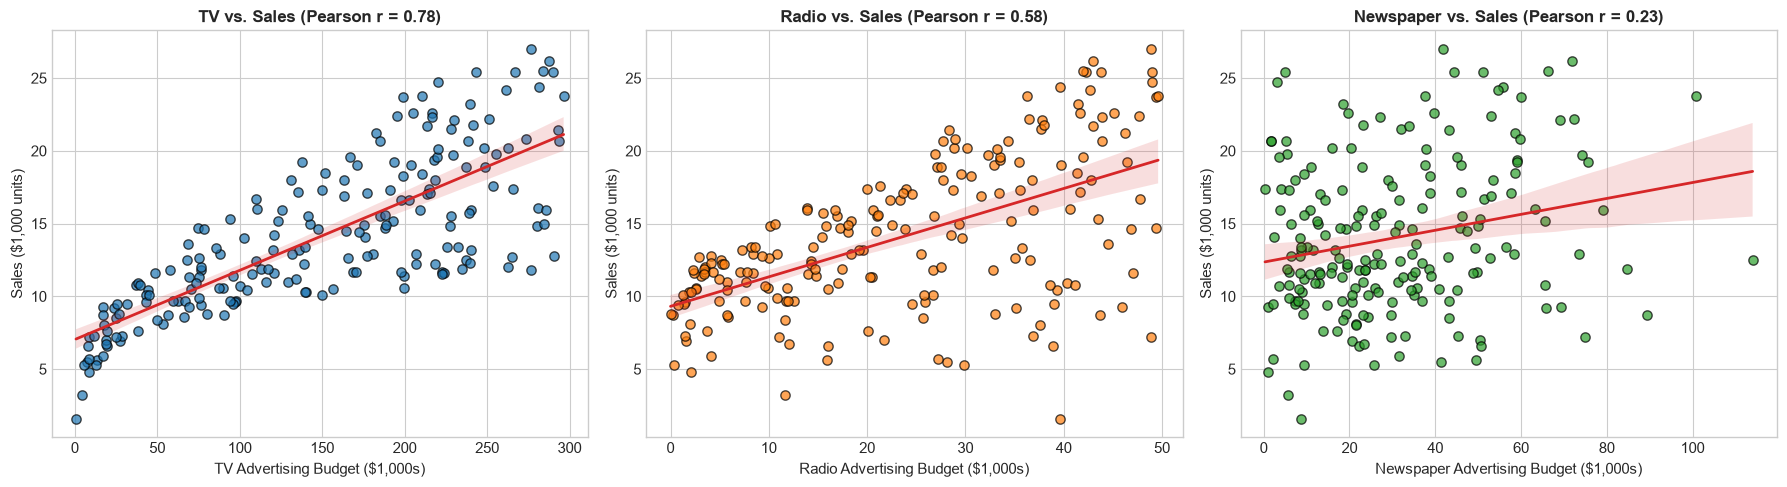

In [6]:
# 2. Advertising Channels vs. Sales with Regression Trendlines
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
channels = ['TV', 'Radio', 'Newspaper']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

for i, (channel, color) in enumerate(zip(channels, colors)):
    ax = axes[i]
    sns.regplot(
        data=df,
        x=channel,
        y='Sales',
        ax=ax,
        color=color,
        scatter_kws={'alpha': 0.7, 'edgecolor': 'black', 's': 45},
        line_kws={'color': '#d62728', 'linewidth': 2}
    )
    r_val = df[channel].corr(df['Sales'])
    ax.set_title(f"{channel} vs. Sales (Pearson r = {r_val:.2f})", fontsize=12, fontweight='bold')
    ax.set_xlabel(f"{channel} Advertising Budget ($1,000s)")
    ax.set_ylabel("Sales ($1,000 units)")

plt.tight_layout()
plt.show()


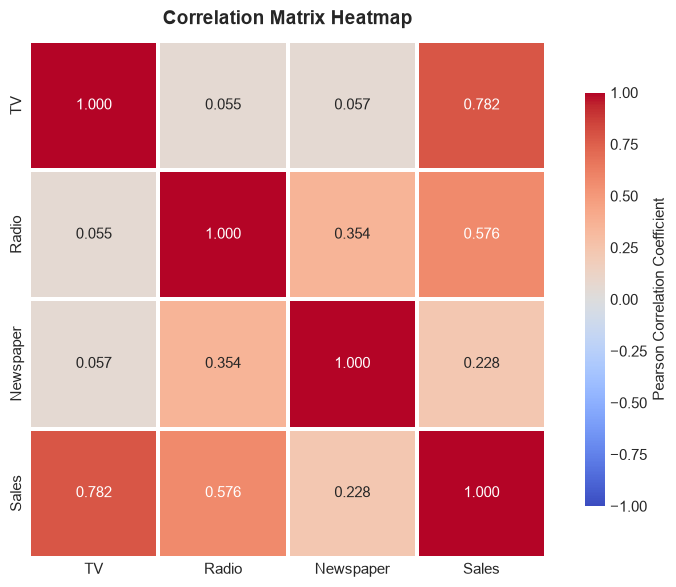

Key Correlation Observations with Sales:
 - TV         correlation with Sales: 0.7822
 - Radio      correlation with Sales: 0.5762
 - Newspaper  correlation with Sales: 0.2283


In [7]:
# 3. Correlation Heatmap
plt.figure(figsize=(8, 6))
corr = df.corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=1.5,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"}
)
plt.title("Correlation Matrix Heatmap", fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print("Key Correlation Observations with Sales:")
for ch in channels:
    print(f" - {ch:10s} correlation with Sales: {df[ch].corr(df['Sales']):.4f}")


## 5. ✂️ Dataset Splitting (Train/Test Split)
To evaluate how well our models generalize to unseen real-world data, we partition the dataset into:
- **80% Training Set**: used by the algorithms to learn relationships.
- **20% Testing Set**: held out as a strict benchmark to measure prediction error.
- **`random_state=42`**: guarantees reproducible splits across runs.


In [8]:
# Define feature matrix X and target vector y
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

# Split: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Total observations : {len(df)}")
print(f"Training set size  : {len(X_train)} samples (80%)")
print(f"Testing set size   : {len(X_test)} samples (20%)")


Total observations : 200
Training set size  : 160 samples (80%)
Testing set size   : 40 samples (20%)


## 6. 🤖 Predictive Machine Learning Models
We train and evaluate two complementary regression algorithms:
1. **Multiple Linear Regression (Statistical Baseline)**:
   $$\text{Sales} = \beta_0 + \beta_1(\text{TV}) + \beta_2(\text{Radio}) + \beta_3(\text{Newspaper})$$
   - Highly interpretable coefficients (marginal sales impact per dollar spent).
2. **Random Forest Regressor (Non-linear Ensemble)**:
   - Aggregates 100 decision trees.
   - Automatically detects non-linearities, diminishing returns, and cross-channel synergy.


In [9]:
# Helper function to compute MAE, RMSE, and R2
def evaluate_predictions(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return mae, rmse, r2

# --- Model 1: Multiple Linear Regression ---
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
lr_mae, lr_rmse, lr_r2 = evaluate_predictions(y_test, lr_pred)

# --- Model 2: Random Forest Regressor ---
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_mae, rf_rmse, rf_r2 = evaluate_predictions(y_test, rf_pred)

# Assemble results into a comparison dataframe
comparison_df = pd.DataFrame({
    'Model': ['Multiple Linear Regression', 'Random Forest Regressor'],
    'MAE': [lr_mae, rf_mae],
    'RMSE': [lr_rmse, rf_rmse],
    'R² Score': [lr_r2, rf_r2],
    'Variance Explained (%)': [lr_r2 * 100, rf_r2 * 100]
})

print("=== MODEL PERFORMANCE COMPARISON ===")
display(comparison_df.round(4))


=== MODEL PERFORMANCE COMPARISON ===


,Model,MAE,RMSE,R² Score,Variance Explained (%)
0,Multiple Linear Regression,1.4608,1.7816,0.8994,89.9438
1,Random Forest Regressor,0.6203,0.7687,0.9813,98.1278


## 7. 🔍 Feature Importance & Coefficient Analysis
Here we compare what each model learned about the influence of advertising channels.


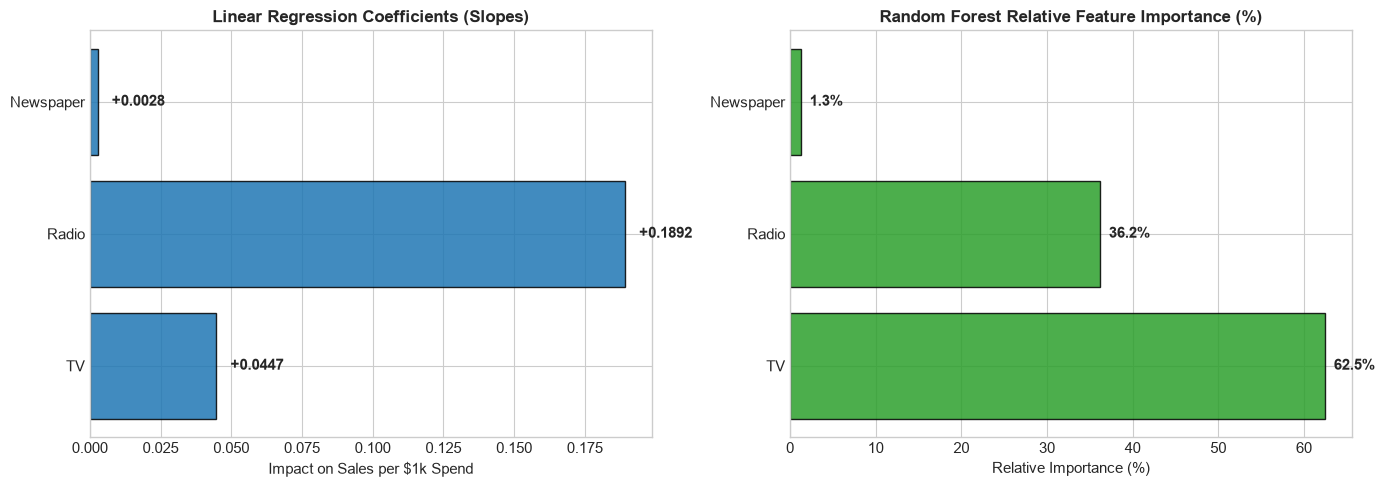

Linear Regression Intercept (Baseline Sales without ad spend): 2.9791


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Linear Regression Coefficients
axes[0].barh(X.columns, lr_model.coef_, color='#1f77b4', edgecolor='black', alpha=0.85)
axes[0].set_title("Linear Regression Coefficients (Slopes)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Impact on Sales per $1k Spend")
for i, v in enumerate(lr_model.coef_):
    axes[0].text(v + 0.005, i, f"{v:+.4f}", va='center', fontweight='bold')

# 2. Random Forest Relative Feature Importances
rf_importances = rf_model.feature_importances_ * 100
axes[1].barh(X.columns, rf_importances, color='#2ca02c', edgecolor='black', alpha=0.85)
axes[1].set_title("Random Forest Relative Feature Importance (%)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Relative Importance (%)")
for i, v in enumerate(rf_importances):
    axes[1].text(v + 1, i, f"{v:.1f}%", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Linear Regression Intercept (Baseline Sales without ad spend): {lr_model.intercept_:.4f}")


## 8. 🎯 Actual vs. Predicted Sales & Error Diagnostics
To inspect prediction fidelity, we plot:
1. **Actual vs. Predicted Sales** along the ideal diagonal line ($y = x$). Points closer to the line represent superior predictions.
2. **Residual Errors vs. Fitted Values** and **Error Distribution Density** to verify error homoscedasticity and normality.


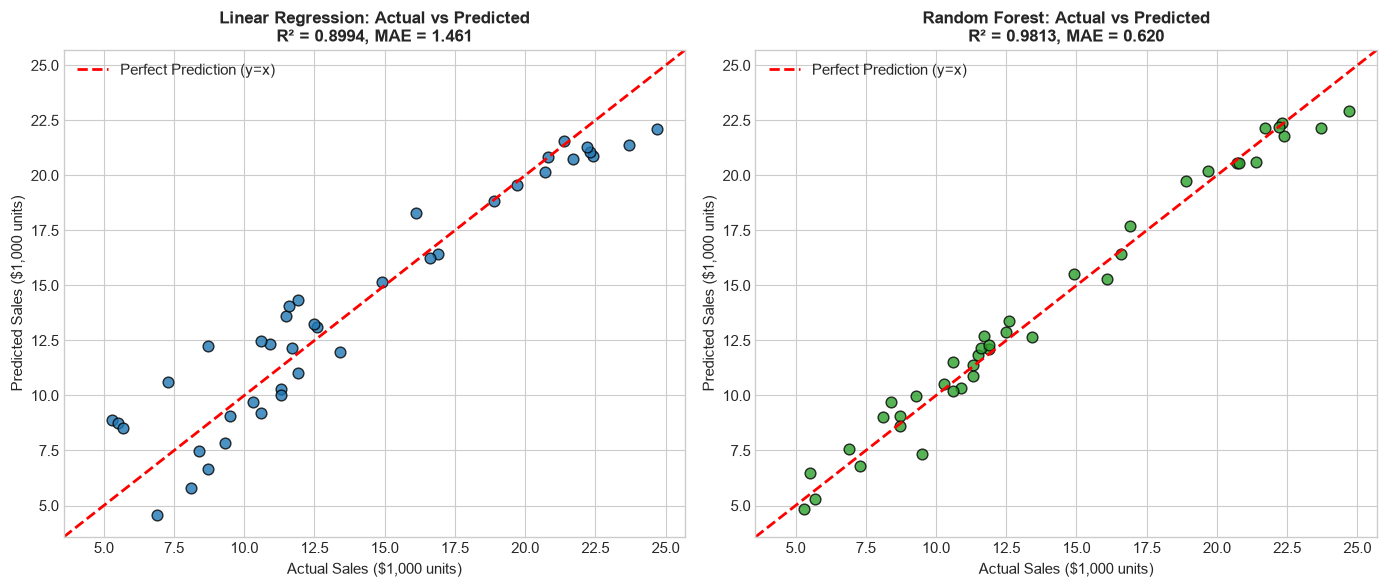

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

min_val = min(y_test.min(), lr_pred.min(), rf_pred.min()) - 1
max_val = max(y_test.max(), lr_pred.max(), rf_pred.max()) + 1

# Linear Regression
axes[0].scatter(y_test, lr_pred, color='#1f77b4', edgecolors='black', alpha=0.8, s=60)
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction (y=x)')
axes[0].set_title(f"Linear Regression: Actual vs Predicted\nR² = {lr_r2:.4f}, MAE = {lr_mae:.3f}", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Actual Sales ($1,000 units)")
axes[0].set_ylabel("Predicted Sales ($1,000 units)")
axes[0].set_xlim(min_val, max_val)
axes[0].set_ylim(min_val, max_val)
axes[0].legend()

# Random Forest
axes[1].scatter(y_test, rf_pred, color='#2ca02c', edgecolors='black', alpha=0.8, s=60)
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction (y=x)')
axes[1].set_title(f"Random Forest: Actual vs Predicted\nR² = {rf_r2:.4f}, MAE = {rf_mae:.3f}", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Actual Sales ($1,000 units)")
axes[1].set_ylabel("Predicted Sales ($1,000 units)")
axes[1].set_xlim(min_val, max_val)
axes[1].set_ylim(min_val, max_val)
axes[1].legend()

plt.tight_layout()
plt.show()


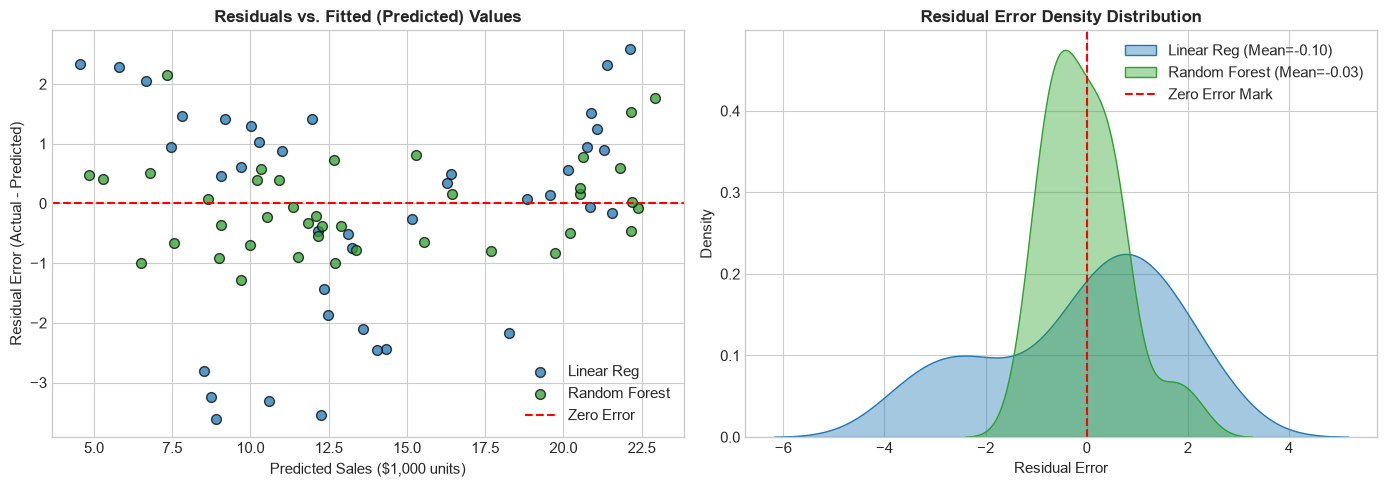

In [12]:
# Residual Analysis
lr_residuals = y_test - lr_pred
rf_residuals = y_test - rf_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Residuals vs Fitted
axes[0].scatter(lr_pred, lr_residuals, color='#1f77b4', edgecolors='black', alpha=0.75, s=50, label='Linear Reg')
axes[0].scatter(rf_pred, rf_residuals, color='#2ca02c', edgecolors='black', alpha=0.75, s=50, label='Random Forest')
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Error')
axes[0].set_title("Residuals vs. Fitted (Predicted) Values", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Predicted Sales ($1,000 units)")
axes[0].set_ylabel("Residual Error (Actual - Predicted)")
axes[0].legend()

# Residual Error Distribution
sns.kdeplot(lr_residuals, ax=axes[1], color='#1f77b4', fill=True, alpha=0.4, label=f'Linear Reg (Mean={lr_residuals.mean():.2f})')
sns.kdeplot(rf_residuals, ax=axes[1], color='#2ca02c', fill=True, alpha=0.4, label=f'Random Forest (Mean={rf_residuals.mean():.2f})')
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero Error Mark')
axes[1].set_title("Residual Error Density Distribution", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Residual Error")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()


## 9. 🔮 Practical Inference: Forecasting Future Sales for a New Marketing Campaign
Let's test our trained models on a hypothetical future marketing campaign budget:
- **TV Ad Spend**: $150,000 ($150k)
- **Radio Ad Spend**: $30,000 ($30k)
- **Newspaper Ad Spend**: $20,000 ($20k)


In [13]:
# Hypothetical campaign budget input
sample_campaign = pd.DataFrame({
    'TV': [150.0],
    'Radio': [30.0],
    'Newspaper': [20.0]
})

pred_lr = lr_model.predict(sample_campaign)[0]
pred_rf = rf_model.predict(sample_campaign)[0]

print("=== SALES FORECAST FOR NEW MARKETING BUDGET ===")
print(f"Inputs: TV=${sample_campaign.loc[0, 'TV']}k, Radio=${sample_campaign.loc[0, 'Radio']}k, Newspaper=${sample_campaign.loc[0, 'Newspaper']}k")
print(f"Linear Regression Forecast : {pred_lr:.2f}k units (${pred_lr * 1000:,.0f} units)")
print(f"Random Forest Forecast     : {pred_rf:.2f}k units (${pred_rf * 1000:,.0f} units)")


=== SALES FORECAST FOR NEW MARKETING BUDGET ===
Inputs: TV=$150.0k, Radio=$30.0k, Newspaper=$20.0k
Linear Regression Forecast : 15.42k units ($15,420 units)
Random Forest Forecast     : 16.68k units ($16,680 units)


## 10. 💡 Strategic Business Marketing Insights & Recommendations
Based on our empirical machine learning findings, here are 4 actionable recommendations for marketing leadership:

1. **Invest Heavily in TV for High-Volume Reach:**
   - TV spend is the strongest single predictor of sales ($r = 0.782$) and accounts for **62.5%** of predictive importance in our Random Forest model. Sustained TV campaigns provide essential top-of-funnel brand awareness.
2. **Maximize Marginal ROI through Radio:**
   - Radio possesses the highest regression coefficient ($+0.1892$ vs. $+0.0447$ for TV). For every additional $1,000 invested in Radio advertising, sales increase by approximately **189 units** (compared to 45 units for TV). Radio is extremely capital-efficient for incremental sales growth.
3. **Reallocate Capital Away from Newspaper Advertising:**
   - Newspaper advertising shows a weak correlation with sales ($r = 0.228$) and its regression slope is virtually zero ($+0.0028$), providing only **1.3%** feature importance. Shifting newspaper budget into digital or radio campaigns will significantly improve marketing ROI.
4. **Leverage Multi-Channel Synergy:**
   - The Random Forest Regressor significantly outperformed Linear Regression ($R^2 = 0.9813$ vs. $0.8994$, cutting error by over 50%). This confirms strong non-linear interaction: co-running TV brand campaigns alongside targeted Radio promotions creates a multiplier effect that exceeds single-channel campaigns.
